In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/placement_predict_50k Dataset.csv')

df = df.drop(columns=['IsAnomaly'])

In [5]:
print(df.columns)

Index(['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream',
       'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1',
       'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6',
       'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships',
       'Projects', 'Workshops', 'Certifications', 'Publications',
       'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore',
       'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus',
       'Salary Package'],
      dtype='object')


In [4]:
y = df['PlacementStatus']
X = df.drop(columns=['PlacementStatus', 'StudentID'])

# Handle categorical features using one-hot encoding
X = pd.get_dummies(X, drop_first=True)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# Initialize and train the Decision Tree Classifier
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

print("DecisionTreeClassifier model trained successfully.")

DecisionTreeClassifier model trained successfully.


Now that the `model` is trained, we can proceed to visualize the decision tree using the `plot_tree` function, as well as evaluate its performance.

[Text(0.3021190068493151, 0.9666666666666667, 'Salary Package <= 1.5\ngini = 0.451\nsamples = 40000\nvalue = [13722, 26278]\nclass = Placed'),
 Text(0.2884203767123288, 0.9, 'gini = 0.0\nsamples = 13674\nvalue = [13674, 0]\nclass = Not Placed'),
 Text(0.29526969178082196, 0.9333333333333333, 'True  '),
 Text(0.3158176369863014, 0.9, 'HistoryOfBacklogs_Yes <= 0.5\ngini = 0.004\nsamples = 26326\nvalue = [48, 26278]\nclass = Placed'),
 Text(0.3089683219178082, 0.9333333333333333, '  False'),
 Text(0.10295376712328767, 0.8333333333333334, 'MockInterviewScore <= 25.35\ngini = 0.001\nsamples = 24066\nvalue = [11, 24055]\nclass = Placed'),
 Text(0.0273972602739726, 0.7666666666666667, 'SGPA_Sem4 <= 8.365\ngini = 0.32\nsamples = 5\nvalue = [1, 4]\nclass = Placed'),
 Text(0.0136986301369863, 0.7, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]\nclass = Placed'),
 Text(0.0410958904109589, 0.7, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]\nclass = Not Placed'),
 Text(0.17851027397260275, 0.7666666666666667,

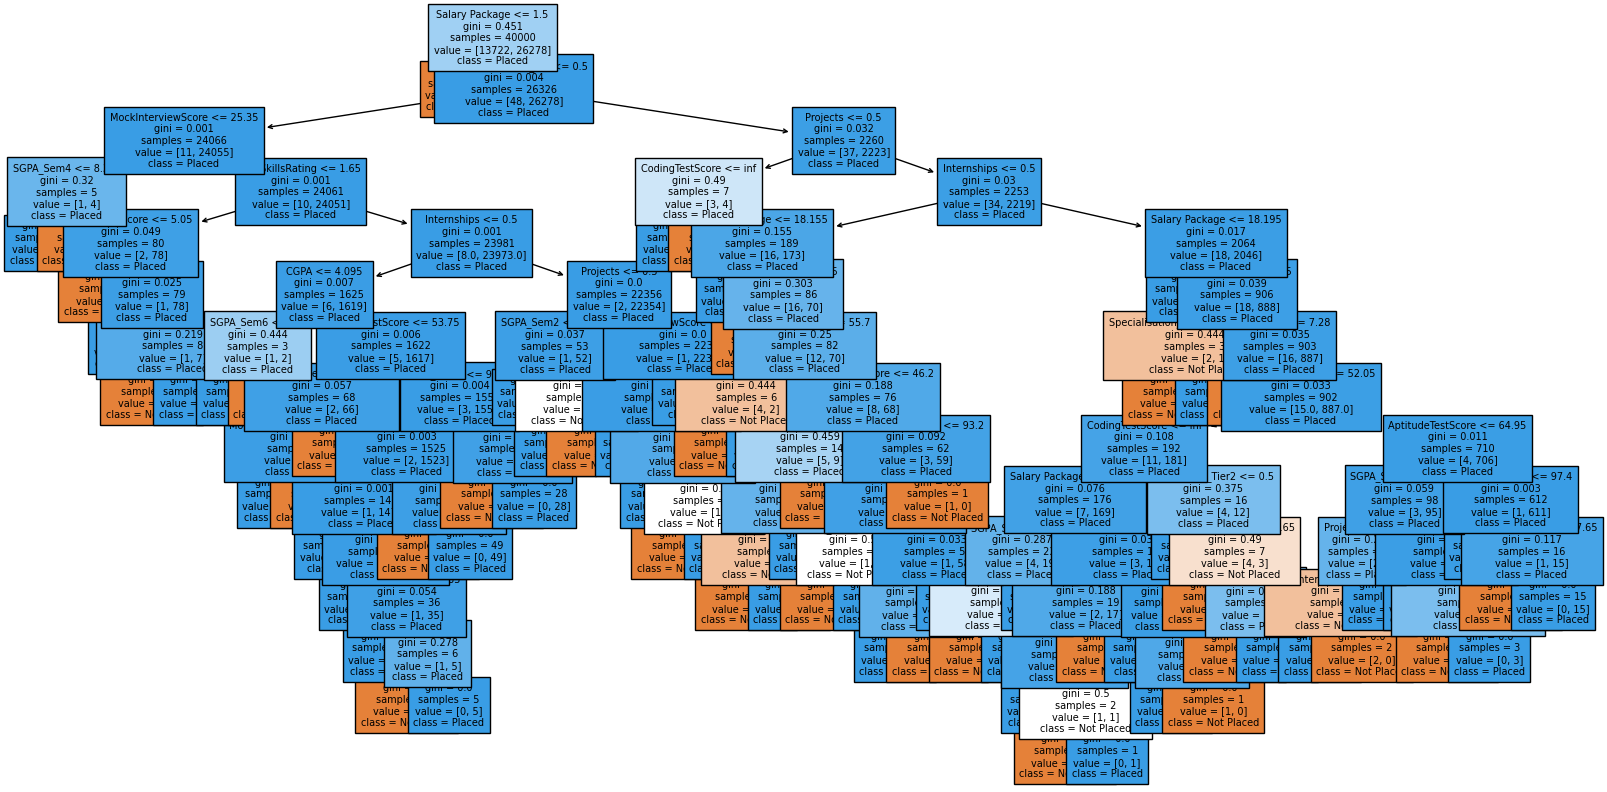

In [7]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Not Placed', 'Placed'],
    filled=True,
    fontsize=7
)

In [8]:
plt.tight_layout()

plt.savefig('decision_tree.png', dpi=150)

print("Saved tree image.")

Saved tree image.


<Figure size 640x480 with 0 Axes>

In [9]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [10]:
RANDOM_STATE = 42

In [13]:
df = pd.read_csv("/content/placement_predict_50k Dataset.csv")

print("Sample of the dataset:")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass balance:")
print(df['PlacementStatus'].value_counts())

TARGET = "PlacementStatus"
DROP_COLS = ["IsAnomaly", "StudentID", "Salary Package"]

# Handle missing values and categorical encoding
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

df_encoded = pd.get_dummies(df.drop(columns=DROP_COLS, errors='ignore'), columns=[
    'Gender', 'City', 'CollegeTier', 'Stream',
    'Specialisation', 'Hostel', 'HistoryOfBacklogs',
    'ExtraCurricular', 'CGPA_Tier'
], drop_first=True)

X = df_encoded.drop(columns=[TARGET])
y = df_encoded[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

rf = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    oob_score=True,
    random_state=RANDOM_STATE
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

print("\nOOB score:", round(rf.oob_score_, 4))
print("Test accuracy:", round(test_accuracy, 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

print("\nFeature importances:")
for name, importance in sorted(
    zip(X.columns, rf.feature_importances_),
    key=lambda x: -x[1]
):
    print(f"{name}: {importance:.4f}")

Sample of the dataset:
   StudentID  Gender       City CollegeTier Stream Specialisation Hostel  \
0          1    Male  Ahmedabad       Tier2    ECE     Networking     No   
1          2  Female     Mumbai       Tier2    ECE    DataScience    Yes   
2          3    Male    Kolkata       Tier2     IT    DataScience    Yes   
3          4    Male     Jaipur       Tier1     CS             AI     No   
4          5    Male       Pune       Tier2     IT    DataScience    Yes   

  HistoryOfBacklogs  SGPA_Sem1  SGPA_Sem2  ...  Publications  \
0                No       6.02       6.54  ...             0   
1               Yes       5.84       5.12  ...             0   
2                No       4.91       5.29  ...             0   
3                No       7.67       8.03  ...             0   
4                No       8.14       8.97  ...             1   

   AptitudeTestScore  SoftSkillsRating  CodingTestScore  MockInterviewScore  \
0               66.7               2.2             49.4 